

## **Project:** Tree Species Image Classification

ResNet18 model setup and training.

Sections 1–12 are shared preparation work. They help me understand the dataset and prepare the images before training. Section 13 is my main individual section.


# Tree Species Classification

In this project, we train computer vision models to recognise tree species from images. The dataset contains 23 classes. In this notebook, I practise the shared data-preparation steps and then focus on ResNet18. I will check how the model is prepared, trained, and saved.



# Import Libraries

In [5]:
import torch.nn as nn
import torch.optim as optim


import matplotlib.pyplot as plt

print("All libraries imported successfully")
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("All libraries imported successfully")

All libraries imported successfully
All libraries imported successfully


# Set the Dataset Paths

The dataset is stored separately from this notebook. Set `data_dir` to the folder that contains the `train`, `val`, and `test` folders. If the path is incorrect, the later cells will not be able to find the images.


### Dataset path

Check the path below before running the notebook. Change it to match where the dataset is saved on your computer.


In [6]:
# Update this path to the location of the downloaded tree dataset
data_dir = r"E:\OneDrive\Desktop\Neural_network\tree"

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

print("Train folder:", train_dir)
print("Validation folder:", val_dir)
print("Test folder:", test_dir)

Train folder: E:\OneDrive\Desktop\Neural_network\tree\train
Validation folder: E:\OneDrive\Desktop\Neural_network\tree\val
Test folder: E:\OneDrive\Desktop\Neural_network\tree\test


# Check the Dataset Folders

Before loading the images, we check whether all three folders exist.

- **Training set:** images used to update the model's weights.
- **Validation set:** images used to monitor performance and choose a checkpoint.
- **Test set:** images reserved for the final evaluation.

In [7]:
print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# Load the Dataset

In [8]:

train_data = datasets.ImageFolder(train_dir)
val_data = datasets.ImageFolder(val_dir)
test_data = datasets.ImageFolder(test_dir)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Explore the Tree Species Classes

Each tree species is treated as a separate class. We print the class names and count them.

The final layer of ResNet18 needs one output for each class, so the number of classes is important when we build the model.


In [9]:
print("Tree species/classes:")

for i, class_name in enumerate(train_data.classes):
    print(i, ":", class_name)

print("\nNumber of classes:", len(train_data.classes))

Tree species/classes:
0 : Acer palmatum
1 : Cedrus deodara
2 : Celtis sinensis
3 : Cinnamomum camphora (Linn) Presl
4 : Elaeocarpus decipiens
5 : Flowering cherry
6 : Ginkgo biloba
7 : Koelreuteria paniculata
8 : Lagerstroemia indica
9 : Liquidambar formosana
10 : Liriodendron chinense
11 : Magnolia grandiflora L
12 : Magnolia liliflora Desr
13 : Michelia chapensis
14 : Osmanthus fragrans
15 : Photinia serratifolia
16 : Platanus
17 : Prunus cerasifera f. atropurpurea
18 : Salix babylonica
19 : Sapindus saponaria
20 : Styphnolobium japonicum
21 : Triadica sebifera
22 : Zelkova serrata

Number of classes: 23


# Count the Images

In [10]:
print("Number of training images:", len(train_data))
print("Number of validation images:", len(val_data))
print("Number of test images:", len(test_data))

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

Number of training images: 3850
Number of validation images: 482
Number of test images: 472

Total images: 4804


# Inspect Example Images


Image size: (1200, 1600)
Label number: 0
Tree species: Acer palmatum


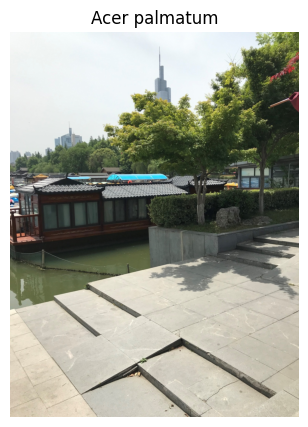

In [11]:
image, label = train_data[0] #gets the first image from the training dataset.

print("Image size:", image.size)
print("Label number:", label)
print("Tree species:", train_data.classes[label])

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

# Explore the Training Images


## 10.1 Display Several Training Images

Viewing several images shows that photos can differ in lighting, viewpoint, background, and the position of the tree. The model should learn useful features of each species rather than rely only on the background.


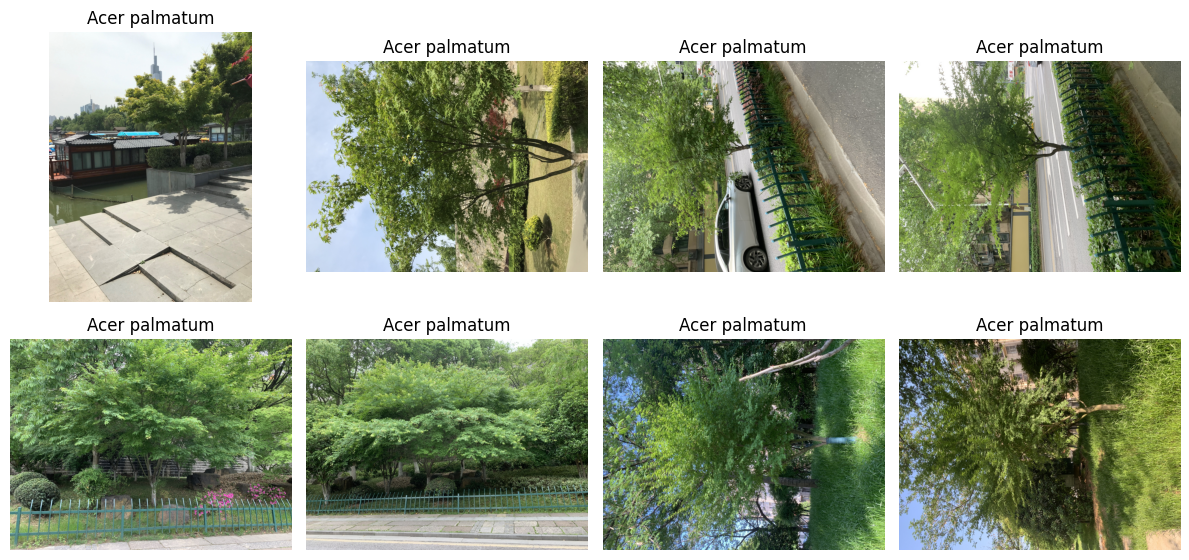

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Check Image Sizes

Images may have different widths and heights.

In [13]:
for i in range(10):
    image, label = train_data[i]
    print(i, train_data.classes[label], image.size)

0 Acer palmatum (1200, 1600)
1 Acer palmatum (1600, 1200)
2 Acer palmatum (1600, 1200)
3 Acer palmatum (1600, 1200)
4 Acer palmatum (1600, 1200)
5 Acer palmatum (1600, 1200)
6 Acer palmatum (1600, 1200)
7 Acer palmatum (1600, 1200)
8 Acer palmatum (1600, 1200)
9 Acer palmatum (1600, 1200)


# Compare Different Tree Species

The dataset is arranged by class, so the first images may come from the same species. Here we display examples from different classes to compare their appearance.


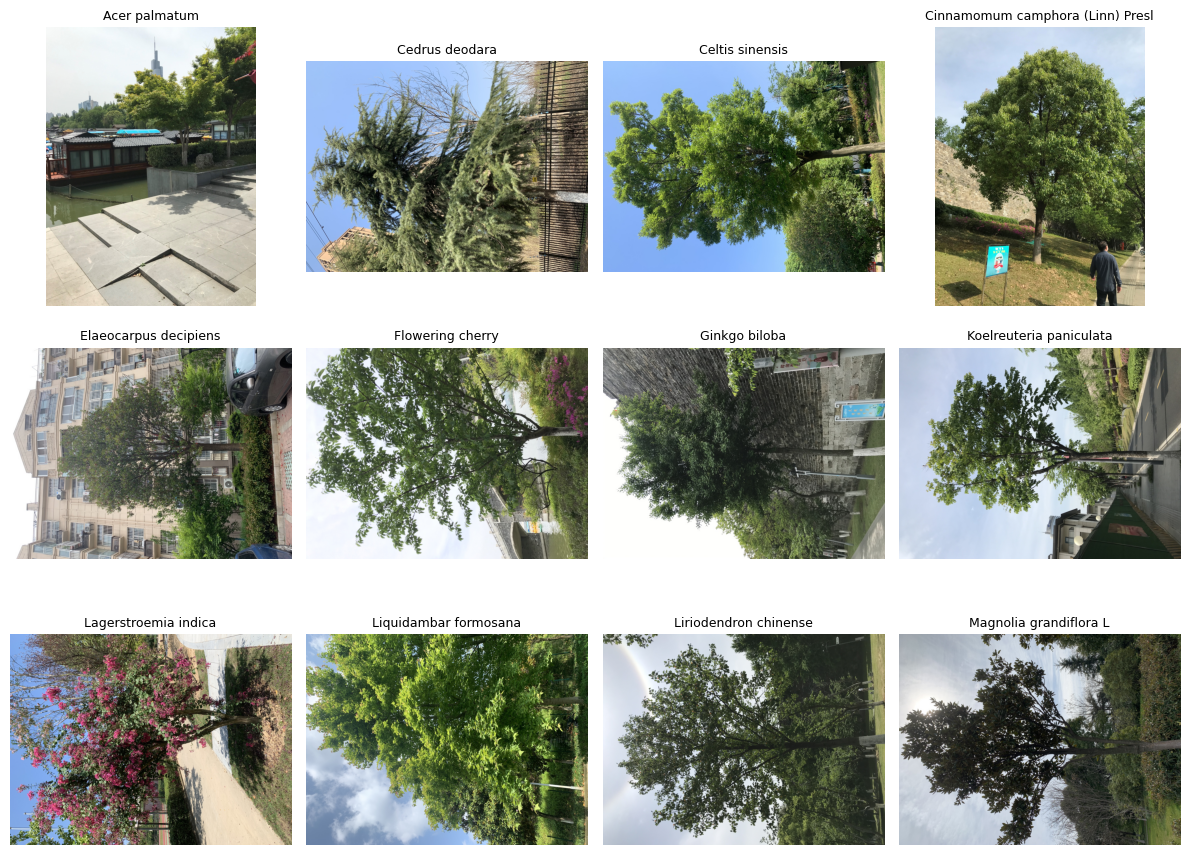

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

# Select one image from 12 different classes
for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]
    
    # Find the first image belonging to this class
    for image_index in range(len(train_data)):
        _, label = train_data[image_index]
        
        if label == i:
            image, _ = train_data[image_index]
            break
    
    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
for class_index in range(10):
    class_name = train_data.classes[class_index]
    
    for image_index in range(len(train_data)):
        image, label = train_data[image_index]
        
        if label == class_index:
            print(class_name, "->", image.size)
            break

Acer palmatum -> (1200, 1600)
Cedrus deodara -> (1600, 1200)
Celtis sinensis -> (1600, 1200)
Cinnamomum camphora (Linn) Presl -> (1200, 1600)
Elaeocarpus decipiens -> (1600, 1200)
Flowering cherry -> (1600, 1200)
Ginkgo biloba -> (1600, 1200)
Koelreuteria paniculata -> (1600, 1200)
Lagerstroemia indica -> (1600, 1200)
Liquidambar formosana -> (1600, 1200)


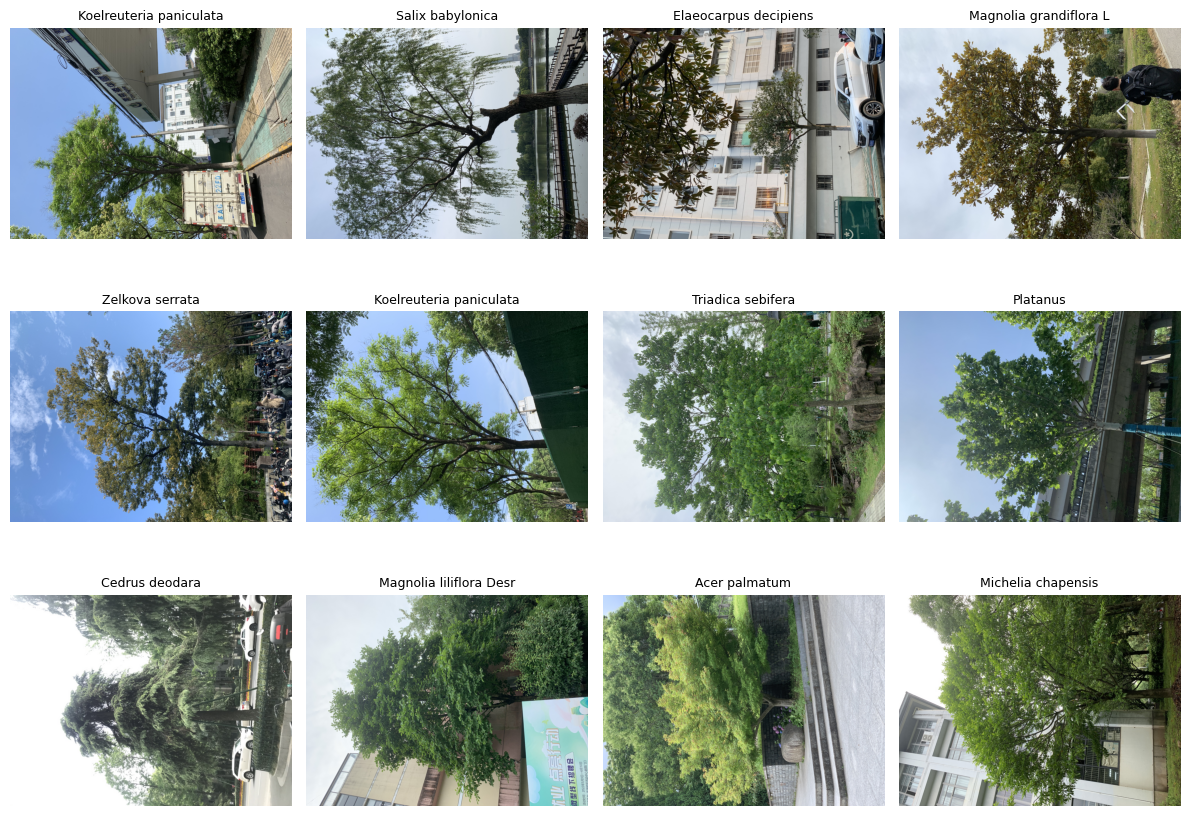

In [16]:
import random

random_indices = random.sample(range(len(train_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, index in zip(axes.flat, random_indices):
    image, label = train_data[index]
    
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
%pip install Pillow

from PIL import Image

image, label = train_data[0]

print("Image:", train_data.classes[label])
print("Image size:", image.size)

exif = image.getexif()

if 274 in exif:
    print("EXIF orientation:", exif[274])
else:
    print("No EXIF orientation information found.")

Note: you may need to restart the kernel to use updated packages.
Image: Acer palmatum
Image size: (1200, 1600)
No EXIF orientation information found.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from collections import Counter

class_counts = Counter(train_data.targets)

print("Training images per class:\n")

for class_index, count in class_counts.items():
    print(train_data.classes[class_index], ":", count)

Training images per class:

Acer palmatum : 162
Cedrus deodara : 125
Celtis sinensis : 188
Cinnamomum camphora (Linn) Presl : 234
Elaeocarpus decipiens : 172
Flowering cherry : 106
Ginkgo biloba : 228
Koelreuteria paniculata : 223
Lagerstroemia indica : 65
Liquidambar formosana : 168
Liriodendron chinense : 182
Magnolia grandiflora L : 212
Magnolia liliflora Desr : 190
Michelia chapensis : 154
Osmanthus fragrans : 173
Photinia serratifolia : 120
Platanus : 193
Prunus cerasifera f. atropurpurea : 99
Salix babylonica : 136
Sapindus saponaria : 224
Styphnolobium japonicum : 157
Triadica sebifera : 154
Zelkova serrata : 185


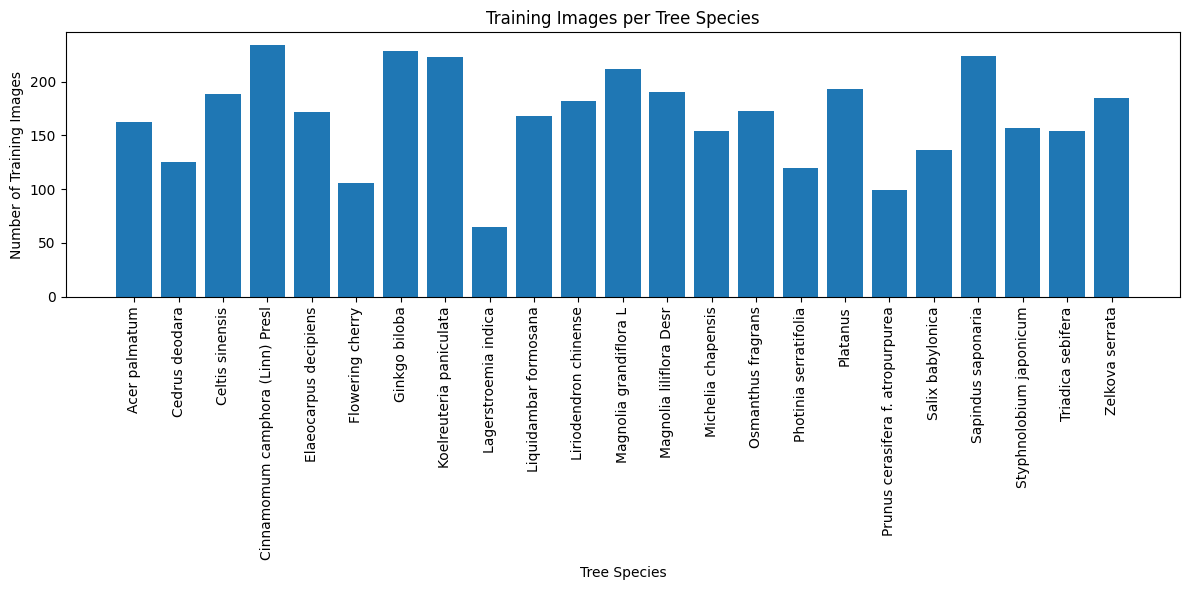

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    train_data.classes,
    [class_counts[i] for i in range(len(train_data.classes))]
)

plt.xlabel("Tree Species")
plt.ylabel("Number of Training Images")
plt.title("Training Images per Tree Species")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# Prepare the Images


## Transformations for Training Images


In [20]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created successfully!")

Training transformations created successfully!


In [21]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation and test transformations created successfully!")

Validation and test transformations created successfully!


In [22]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Transformed datasets created successfully!")

Transformed datasets created successfully!


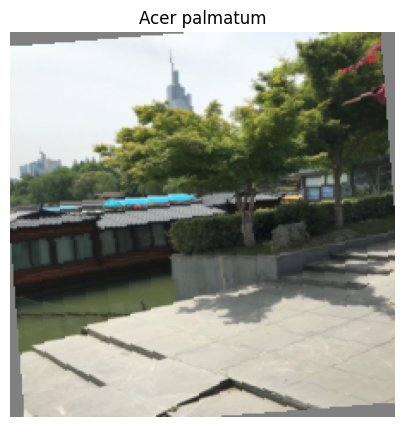

Processed image shape: torch.Size([3, 224, 224])


In [23]:
image, label = train_dataset[0]

# Reverse ImageNet normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image.numpy().transpose(1, 2, 0)
image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Processed image shape:", image.shape)

# Create DataLoaders
- use batch size of 32

In [24]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [25]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First few labels: tensor([ 1,  5,  7,  4, 11,  0, 11,  9,  6,  3])


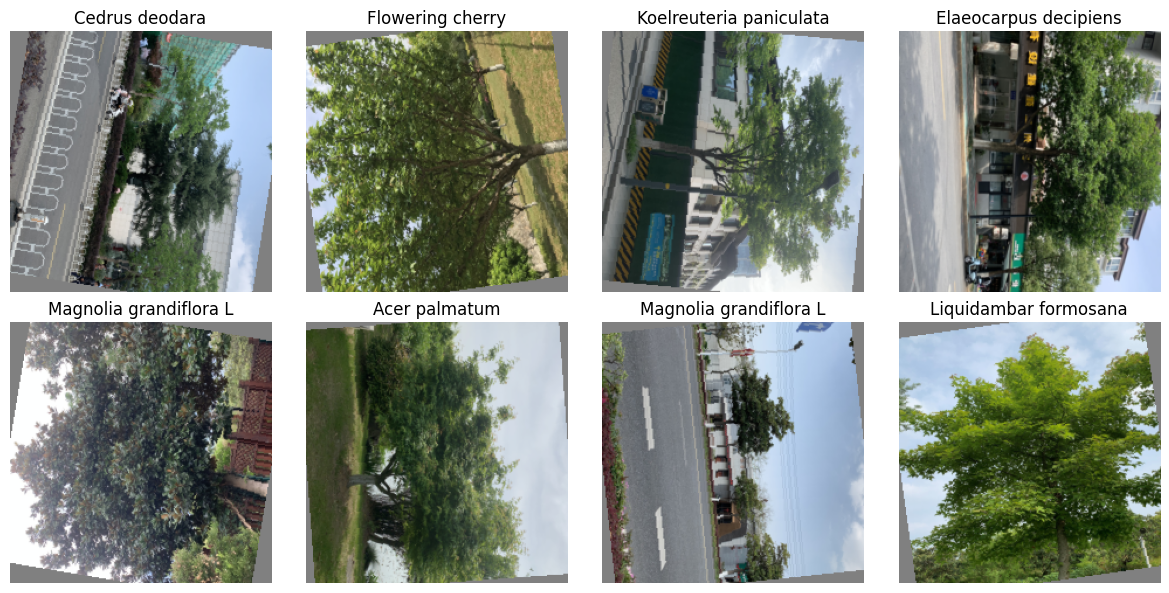

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):

    image = images[i].numpy().transpose(1, 2, 0)

    # Reverse normalization for display
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

# ResNet18 Model Development and Training

This is my main individual section. I use ResNet18, a convolutional neural network that was pretrained on ImageNet, and adapt it to classify the 23 tree species in this dataset. Instead of training every feature from the beginning, I started with learned image features and replace the final classification layer for our task. In the final experiment below, all model parameters are passed to the Adam optimiser, so the model is fine-tuned rather than training only the final layer.


## Set Up Transfer Learning

Used the pretrained ResNet18 weights `IMAGENET1K_V1`. ResNet18 has learned useful image features from ImageNet, and adapt its final layer to output one score for each of our 23 tree species. And, use cross-entropy loss to measure prediction error and Adam to update the model parameters. The learning rate is `0.0001`, the batch size is 32, and training runs for five epochs. The validation set helps us choose the best checkpoint.


In [27]:
num_classes = len(train_dataset.classes)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Number of classes:", num_classes)
print("PyTorch version:", torch.__version__)
print("Using device:", device)

Number of classes: 23
PyTorch version: 2.11.0+cpu
Using device: cpu


## Create a Function That Saves the Best Model

Validation accuracy can change from one epoch to the next, so the final epoch is not always the best one.The function below records training and validation loss and accuracy. Whenever validation accuracy improves, it saves the model weights to the checkpoint file. This lets us reload the best version later.
s you read the code, look for the differences between `model.train()` and `model.eval()`, and notice that validation runs inside `torch.no_grad()`.


In [28]:
def train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, save_path):
    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    best_val_accuracy = 0.0

    for epoch in range(epochs):

        # -------------------------
        # Training
        # -------------------------

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_accuracy = 100 * correct / total

        # -------------------------
        # Validation
        # -------------------------

        model.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = running_loss / len(val_loader)
        val_accuracy = 100 * correct / total

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        # -------------------------
        # Save best model
        # -------------------------

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                save_path
            )

            print(f"Best model saved to {save_path}")

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Train Accuracy: {train_accuracy:.2f}% "
            f"Val Loss: {val_loss:.4f} "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

    print("Best validation accuracy:", best_val_accuracy)

    return (
        train_losses,
        val_losses,
        train_accuracies,
        val_accuracies
    )

## Prepare the Final ResNet18 Model

We create a fresh pretrained ResNet18 and replace its final layer with a new layer for the 23 tree species. We then move the model to the selected device, either a GPU or CPU.

The validation set is used to choose the best checkpoint. The test set is kept for final evaluation and is not used to train the model.


In [29]:
# Create a fresh ResNet18 model

model18 = models.resnet18(weights="IMAGENET1K_V1")

# Replace the final classification layer

model18.fc = nn.Linear(
    model18.fc.in_features,
    num_classes
)

# Move model to the selected device

model18 = model18.to(device)

print("Fresh ResNet18 created successfully")
print("Number of classes:", num_classes)

Fresh ResNet18 created successfully
Number of classes: 23


In [30]:
# Loss function

criterion = nn.CrossEntropyLoss()

# Optimizer

optimizer = optim.Adam(
    model18.parameters(),
    lr=0.0001
)

print("Loss function and optimizer created successfully")

Loss function and optimizer created successfully


## Train the Final ResNet18 Model
Traning ResNet18 for five epochs. After each epoch, the training function checks validation performance and saves the model if validation accuracy reaches a new best value.


In [31]:
# Number of epochs for the final training

epochs = 5

# Train ResNet18 and keep the best validation model

train_losses18, val_losses18, train_accuracies18, val_accuracies18 = train_model_best(
    model18,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    "resnet18_best.pth"
)

Best model saved to resnet18_best.pth
Epoch [1/5] Train Loss: 1.7992 Train Accuracy: 51.87% Val Loss: 0.8306 Val Accuracy: 78.01%
Best model saved to resnet18_best.pth
Epoch [2/5] Train Loss: 0.6499 Train Accuracy: 83.66% Val Loss: 0.5196 Val Accuracy: 86.10%
Best model saved to resnet18_best.pth
Epoch [3/5] Train Loss: 0.3401 Train Accuracy: 92.00% Val Loss: 0.3521 Val Accuracy: 88.80%
Best model saved to resnet18_best.pth
Epoch [4/5] Train Loss: 0.2074 Train Accuracy: 95.79% Val Loss: 0.3147 Val Accuracy: 90.46%
Epoch [5/5] Train Loss: 0.1495 Train Accuracy: 96.68% Val Loss: 0.3294 Val Accuracy: 89.42%
Best validation accuracy: 90.45643153526972


In [32]:
import os

model_path = "resnet18_best.pth"

if os.path.exists(model_path):
    print("Best ResNet18 model file found!")
    print("File:", model_path)
else:
    print("Best model file was not found.")

Best ResNet18 model file found!
File: resnet18_best.pth


In [33]:
model18.load_state_dict(torch.load("resnet18_best.pth", map_location=device))

model18 = model18.to(device)

print("Best ResNet18 model loaded successfully!")

Best ResNet18 model loaded successfully!
